![banner-pdi](https://user-images.githubusercontent.com/58775072/141189378-b5df3287-e8c0-48a1-ad11-825ba317463b.png)

## Universidade Federal de Campina Grande (UFCG)
## Centro de Engenharia Elétrica e Informática (CEEI) 
## Disciplina: Int. ao Processamento de Imagem Digital e Visão Computacional
## Professora: Luciana Ribeiro Veloso
## Aluno(a): Coloque seu nome aqui

## Observações
***

1. Os arquivos de laboratório devem ser salvos seguindo o seguinte padrão: `lab-x-nome-sobrenome.ipynb`.
2. Não esqueça de colocar o seu nome no cabeçalho acima.
3. Não altere a ordem das células e realize as implementações somente nos campos específicados.  
4. Ao longo do laboratório será solicitado perguntas teóricas relativas aos assuntos das aulas da disciplina e implementações de código utilizando a linguagem de programação Python. 
5. As células de implementação com código serão indicadas pelos seguintes comentários: `# IMPLEMENTE O SEU CÓDIGO AQUI`.
6. Para editar uma célula de texto, basta clicar duas vezes com o cursos do mouse para editar, e `Ctrl + Enter` para finalizar a edição. 
7. Para rodar as células com os códigos desenvolvidos, digite `Ctrl + Enter` ou clique em `Run` no menu do Jupyter.
8. Dúvidas, problemas de execução de código ou dificuldades com a linguagem de programação Python devem ser feitas durante as aulas de laboratório, encaminhadas para o grupo de WhatsApp da turma ou fórum do PVAE da disciplina.
9. Os laboratórios devem ser enviados nos campos especificados pelo PVAE. ATENTE-SE AOS PRAZOS DE ENTREGA!

# <span style='color:red'>Laboratório 6: Redes Neurais Artificiais</span>
***

### Importação dos Pacotes

In [15]:
import os                                                 # operational system para manipulação de arquivos.
import cv2                                                # opencv para manipulação de imagens.
import numpy as np                                        # numpy para manipulação de matrizes e arrays.
import matplotlib.pyplot as plt                           # pyplot para plotagem de gráficos e imagens.
from sklearn.model_selection import train_test_split      # função para particionamento dos dados
from tensorflow.keras.models import Sequential            # classe de modelos sequenciais para construir as redes neurais.
from tensorflow.keras.layers import Dense, Input, Dropout # camada de neurônios densamente conectados.
from tensorflow.keras.optimizers import SGD               # otimizador "Descida do Gradiente com Momento".
from tensorflow.keras.datasets import boston_housing      # dataset utilizado nesse experimento.

### Banco de Dados
* Vamos utilizar um banco de dados do catálogo de datasets do Keras, que é disponibilizado como uma função pronta;

* Cada instância do banco de dados corresponde a um conjunto de 13 valores referentes a características de subúrbios de Boston na década de 1970, a exemplo de taxa de crimes, imposto sobre propriedade, etc;

* Esses valores serão utilizados para calcular o valor mediano das residências no respectivo subúrbio em um problema de regressão, de modo que iremos mapear um vetor de entrada com 13 valores em um vetor de saída com 1 único elemento;

* O banco de dados contém 506 valores divididos em 404 instâncias de treino e 102 de teste;

* Uma descrição mais detalhada dos valores de entrada pode ser vista em http://lib.stat.cmu.edu/datasets/boston, onde os valores são descritos na ordem que aparecem;

### Organização do banco de dados

* Comumente os dados utilizados no treinamento de modelos de inteligência artificial reservam a primeira dimensão para controlar a amostra e espalham o tipo de dado utilizado nas demais dimensões do tensor. 


* Nesse caso, os nossos dados são vetores de características unidimensionais (1D), de modo que são organizados em tensores bidimensionais (2D) com formato: **dados.shape = (amostras, características)**
    * O i-ésimo exemplo pode ser acessado a partir de: **exemplo = dados[i]**
    * A j-ésima característica dos exemplos pode ser acessada a partir de: **caracteristica = dados[:, j]**
    * Porções do tensor podem ser acessadas utilizando fatiamento, por exemplo:
        * primeiros_5_exemplos = dados[:5]
        * caracteristicas_9a13 = dados[8:13]
        

* Lembrem-se que a contagem de índices em Python começa em 0 e só é inclusiva no primeiro elemento:
    * **:5** produz os índices **0, 1, 2, 3, 4** 
    * **8:13** produz os índices **8, 9, 10, 11, 12** 
        

* O banco de dados pode ser carregado utilizando:
    * **(train_data, train_targets), (test_data, test_targets) = boston_housing.load_data()**
    * train_data é um tensor com as entradas do conjunto de treino;
    * test_data é um tensor com as entradas do conjunto de teste;
    * train_targets é um tensor com os gabaritos do conjunto de treino;
    * test_targets é um tensor com os gabaritos do conjunto de teste;

## <span style='color:blue'>Questão 1: [Valor da Questão: 2.0][Taxa de acerto: x.x]</span>

* (a) O código abaixo carrega o banco de dados, acesse alguns exemplos de treinamento e de teste e veja suas dimensões.
    * Use índices entre **[0, 404]** para os dados de treino e entre **[0, 102]** para os de teste.

* (b) Verifique as dimensões e as faixas de valores de cada característica nos vetores de entrada dos conjuntos de treino e de teste. A faixa de valores das características são semelhantes? E os dados de treino e de teste?**</span>
    * Encontre os valores mínimo/máximo além da média **(np.mean)** e da variância **(np.var)** de cada uma das 13 características.
    * Sugestão: leia sobre o parâmetro "axis" na documentação das funções **np.min**, **np.max** e **np.mean**.
* (c) Verifique as dimensões e as faixas de valores dos gabaritos dos conjuntos de treino e de teste. Os valores encontrados são semelhantes?

In [16]:
(train_data, train_targets), (test_data, test_targets) = boston_housing.load_data()

In [17]:
# IMPLEMENTE SEU CÓDIGO AQUI --> QUESTÃO 1 - letra (a)
print('Dimensão dos Dados de Treinamento: ', train_data.shape)
print('Dimensão dos Rótulos nos Dados de Treinamento: ', train_targets.shape)
print('Dimensão dos Dados de Teste: ', test_data.shape)
print('Dimensão dos Rótulos nos Dados de Teste: ', test_targets.shape)

print('Exemplo dos Dados de Entrada:\n', train_data[0])
print('\nExemplo dos Dados de Saída:\n', train_targets[0])

Dimensão dos Dados de Treinamento:  (404, 13)
Dimensão dos Rótulos nos Dados de Treinamento:  (404,)
Dimensão dos Dados de Teste:  (102, 13)
Dimensão dos Rótulos nos Dados de Teste:  (102,)
Exemplo dos Dados de Entrada:
 [  1.23247   0.        8.14      0.        0.538     6.142    91.7
   3.9769    4.      307.       21.      396.9      18.72   ]

Exemplo dos Dados de Saída:
 15.2


|**Características dos Dados de Entrada**|**Descrição**|
|:-:|:-|
|**CRIM**|     <span style='color:red'>per capita crime rate by town</span>|
|**ZN**|       <span style='color:red'>proportion of residential land zoned for lots over 25,000 sq.ft.</span>|
|**INDUS**|    <span style='color:red'>proportion of non-retail business acres per town</span>|
|**CHAS**|     <span style='color:red'>Charles River dummy variable (= 1 if tract bounds river; 0 otherwise)</span>|
|**NOX**|      <span style='color:red'>nitric oxides concentration (parts per 10 million)</span>|
|**RM**|       <span style='color:red'>average number of rooms per dwelling</span>|
|**AGE**|      <span style='color:red'>proportion of owner-occupied units built prior to 1940</span>|
|**DIS**|      <span style='color:red'>weighted distances to five Boston employment centres</span>|
|**RAD**|      <span style='color:red'>index of accessibility to radial highways</span>|
|**TAX**|      <span style='color:red'>full-value property-tax rate per \$10,000</span>|
|**PTRATIO**|  <span style='color:red'>pupil-teacher ratio by town</span>|
|**B**|        <span style='color:red'>$1000(B_k - 0.63)^2$ where Bk is the proportion of blacks by town</span>|
|**LSTAT**|    <span style='color:red'>\% lower status of the population</span>|

|**Características dos Dados de Saída**|**Descrição**|
|:-:|:-|
|**MEDV**|     <span style='color:red'>Median value of owner-occupied homes in \$1000's</span>|

In [18]:
# IMPLEMENTE SEU CÓDIGO AQUI --> QUESTÃO 1 - letra (b)
min_train_x = np.min(train_data, axis = 0)
max_train_x = np.max(train_data, axis = 0)
mean_train_x = np.mean(train_data, axis = 0)
var_train_x = np.var(train_data, axis = 0)

print('Dados de Treino:\n--')
for i in range(1, 14):
    print('{} - Limite: [{:.2f},{:.2f}], com Média {:.2f} e Variância {:.2f}'.format(i, min_train_x[i - 1], 
                                                                                     max_train_x[i - 1],
                                                                                     mean_train_x[i - 1], 
                                                                                     var_train_x[i - 1]))
min_test_x = np.min(test_data, axis = 0)
max_test_x = np.max(test_data, axis = 0)
mean_test_x = np.mean(test_data, axis = 0)
var_test_x = np.var(test_data, axis = 0)

print('\nDados de Teste:\n--')
for i in range(1, 14):
    print('{} - Limite: [{:.2f},{:.2f}], com Média {:.2f} e Variância {:.2f}'.format(i, min_test_x[i - 1], 
                                                                                     max_test_x[i - 1],
                                                                                     mean_test_x[i - 1], 
                                                                                     var_test_x[i - 1]))

Dados de Treino:
--
1 - Limite: [0.01,88.98], com Média 3.75 e Variância 85.18
2 - Limite: [0.00,100.00], com Média 11.48 e Variância 563.51
3 - Limite: [0.46,27.74], com Média 11.10 e Variância 46.28
4 - Limite: [0.00,1.00], com Média 0.06 e Variância 0.06
5 - Limite: [0.39,0.87], com Média 0.56 e Variância 0.01
6 - Limite: [3.56,8.72], com Média 6.27 e Variância 0.50
7 - Limite: [2.90,100.00], com Média 69.01 e Variância 778.75
8 - Limite: [1.13,10.71], com Média 3.74 e Variância 4.11
9 - Limite: [1.00,24.00], com Média 9.44 e Variância 75.47
10 - Limite: [188.00,711.00], com Média 405.90 e Variância 27611.97
11 - Limite: [12.60,22.00], com Média 18.48 e Variância 4.83
12 - Limite: [0.32,396.90], com Média 354.78 e Variância 8834.99
13 - Limite: [1.73,37.97], com Média 12.74 e Variância 52.50

Dados de Teste:
--
1 - Limite: [0.01,25.05], com Média 3.09 e Variância 28.59
2 - Limite: [0.00,90.00], com Média 10.90 e Variância 460.83
3 - Limite: [1.22,27.74], com Média 11.26 e Variância 

In [19]:
# IMPLEMENTE SEU CÓDIGO AQUI -QUESTÃO 1 - letra (c)
print('Dados de Treino:\n--')
min_train_x = np.min(train_targets, axis = 0)
max_train_x = np.max(train_targets, axis = 0)
mean_train_x = np.mean(train_targets, axis = 0)
var_train_x = np.var(train_targets, axis = 0)

print('{} - Limite: [{:.2f},{:.2f}], com Média {:.2f} e Variância {:.2f}'.format(14, min_train_x, 
                                                                                     max_train_x,
                                                                                     mean_train_x, 
                                                                                     var_train_x))
print('\nDados de Teste:\n--')
min_train_x = np.min(test_targets, axis = 0)
max_train_x = np.max(test_targets, axis = 0)
mean_train_x = np.mean(test_targets, axis = 0)
var_train_x = np.var(test_targets, axis = 0)

print('{} - Limite: [{:.2f},{:.2f}], com Média {:.2f} e Variância {:.2f}'.format(14, min_train_x, 
                                                                                     max_train_x,
                                                                                     mean_train_x, 
                                                                                     var_train_x))

Dados de Treino:
--
14 - Limite: [5.00,50.00], com Média 22.40 e Variância 84.62

Dados de Teste:
--
14 - Limite: [5.60,50.00], com Média 23.08 e Variância 83.24


## <span style='color:green'>Respostas da Questão 1:</span>

* (a) Os valores estatísticos variam entre cada uma das características, isso ocorre devido a distinção das características, já que cada uma delas indica parâmetros distintos sobre os subúrbios de Boston;
* (b) Comparando as características dos dados de treinamento e dos dados de teste, é perceptível que ambos possuem o mesmo grau de estratíficação, mas correspondem a dados distintos;
* (c) As mesmas considerações feitas na (1.1-b) podem ser generalizadas para os Rótulos de Treinamento e Teste, a única diferença é que há apenas uma característica a ser predita pelo modelo.

### Pre-processamento dos dados

* Dados cujas características assumem diferentes faixas de valores muitas vezes são problemáticos para o aprendizado dos modelos e podem reduzir a velocidade de convergência ou até mesmo limitar as capacidades do modelo final.

* Nesse sentido, uma prática comum é a normalização dos dados antes do treinamento, que geralmente é feito por característica em forma da subtração da média e divisão pelo desvio padrão, o que faz com que os dados resultantes tenham média 0 e variância 1.

* Um ponto muito importante é que a normalização deve ser feita partir dos mesmos valores em todos os conjuntos, ou seja, os dados são normalizados segundo informações do conjunto de treino.

* Na prática não temos como calcular a média e variância real, mas se os dados de treino são significativos os seus valores são suficientes.

In [20]:
# Calcula a média do conjunto de treino
mean = train_data.mean(axis = 0)
# Calcula o desvio padrão do conjunto de treino
std = train_data.std(axis = 0)
# Normaliza os dados de treino
train_data -= mean
train_data /= std
# Normaliza os dados de teste
test_data -= mean
test_data /= std

## <span style='color:blue'>Questão 2: [Valor da Questão: 1.0][Taxa de acerto: x.x]</span>

* Repita o item b da primeira questão para os dados normalizados. O que se observa quantos aos valores de média e variância para os dados de treino e teste? Comente a sua interpretação sobre as diferenças observadas.

In [21]:
# IMPLEMENTE SEU CÓDIGO AQUI --> QUESTÃO 2
print('Dados de Treino:\n--')
min_train_x = np.min(train_data, axis = 0)
max_train_x = np.max(train_data, axis = 0)
mean_train_x = np.mean(train_data, axis = 0)
var_train_x = np.var(train_data, axis = 0)

for i in range(1, 14):
    print('{} - Limite: [{:.2f},{:.2f}], com Média {:.2f} e Variância {:.2f}'.format(i, min_train_x[i - 1], 
                                                                                     max_train_x[i - 1],
                                                                                     mean_train_x[i - 1], 
                                                                                     var_train_x[i - 1]))
print('\nDados de Teste:\n--')
min_test_x = np.min(test_data, axis = 0)
max_test_x = np.max(test_data, axis = 0)
mean_test_x = np.mean(test_data, axis = 0)
var_test_x = np.var(test_data, axis = 0)

for i in range(1, 14):
    print('{} - Limite: [{:.2f},{:.2f}], com Média {:.2f} e Variância {:.2f}'.format(i,min_test_x[i - 1], 
                                                                                     max_test_x[i - 1],
                                                                                     mean_test_x[i - 1], 
                                                                                     var_test_x[i - 1]))

Dados de Treino:
--
1 - Limite: [-0.41,9.23], com Média -0.00 e Variância 1.00
2 - Limite: [-0.48,3.73], com Média 0.00 e Variância 1.00
3 - Limite: [-1.56,2.45], com Média 0.00 e Variância 1.00
4 - Limite: [-0.26,3.89], com Média -0.00 e Variância 1.00
5 - Limite: [-1.47,2.68], com Média -0.00 e Variância 1.00
6 - Limite: [-3.82,3.47], com Média 0.00 e Variância 1.00
7 - Limite: [-2.37,1.11], com Média 0.00 e Variância 1.00
8 - Limite: [-1.29,3.44], com Média 0.00 e Variância 1.00
9 - Limite: [-0.97,1.68], com Média 0.00 e Variância 1.00
10 - Limite: [-1.31,1.84], com Média -0.00 e Variância 1.00
11 - Limite: [-2.67,1.60], com Média 0.00 e Variância 1.00
12 - Limite: [-3.77,0.45], com Média 0.00 e Variância 1.00
13 - Limite: [-1.52,3.48], com Média 0.00 e Variância 1.00

Dados de Teste:
--
1 - Limite: [-0.40,2.31], com Média -0.07 e Variância 0.34
2 - Limite: [-0.48,3.31], com Média -0.02 e Variância 0.82
3 - Limite: [-1.45,2.45], com Média 0.02 e Variância 1.07
4 - Limite: [-0.26,3.8

## <span style='color:green'>Resposta da Questão 2:</span>

* Analisando os valores estatísticos com os Dados Normalizados, é perceptível que o valor médio de cada uma das características foi configurada como 0 e a variância como 1 nos Dados de Treinamento. Essas técnicas permitem, além de reduzir o custo computacional na hora de treinar modelos com dados normalizados, destacam com mais qualidade as características sem alterar a sua essência. Utilizando a média e a variância obtida com os Dados de Treinamento, os Dados de Teste foram normalizados, mas apresentam valores médios e de variância um pouco distintos de 0 e 1, respectivamente. Esse tipo de configuração é ideal para tornar os dados de teste mais próximos dos dados de treinamento de forma automatizada, permitindo um melhor resultado nas métricas de avaliação.

Agora vamos criar uma partição de validação a partir do conjunto de treino para realizar uma validação cruzada. Vamos utilizar a função **train_test_split**, que separa dados e os seus respectivos gabaritos segundo uma fração especificada.

In [22]:
# fração escolhida para separar o mesmo número de instâncias do conjunto de testes
data_frac = test_data.shape[0] / train_data.shape[0]

# criação do conjunto de validação
train_data, val_data, train_targets, val_targets = train_test_split(train_data,             # dados de treino
                                                                    train_targets,          # gabaritos de treino
                                                                    test_size = data_frac,  # proporção de dados p/ validação
                                                                    random_state = 42)      # semente de geração

print("Treino:", train_data.shape, train_targets.shape)
print("Validação:", val_data.shape, val_targets.shape)

Treino: (302, 13) (302,)
Validação: (102, 13) (102,)


### Construindo o modelo

Para construir o modelo usaremos a classe **Sequential**, que possibilita a construção de modelos sequenciais de forma bastante simples.
* A construção do modelo é feita a partir do seu instanciamento como objeto da classe seguido de chamadas à função **add()** para adicionar camadas.
* Como estamos construindo apenas Redes Neurais Artificiais por enquanto, vamos utilizar apenas as camadas **Dense** e **Input**.
    * A camada Input cria a entrada da rede com **Input(shape = None )**
        * shape corresponde ao formato do tensor de entrada, no nosso caso será o número de características do nosso banco de dados (13);
    * A camada Dense pode ser chamada com **Dense(n_unidades, activation = 'linear' )**
        * n_unidades corresponde ao número de neurônios da camada;
        * activation corresponde à função de ativação utilizada na camada;
* Algumas funções de ativação disponíveis são:
    * "linear"
    * "relu"
    * "sigmoid"
    * "softmax"
    * "tanh"


* Mais informações sobre a camada dense podem ser vistas em **https://keras.io/api/layers/core_layers/dense/**
* Mais informações sobre as ativações disponíveis podem ser vistas em **https://keras.io/api/layers/activations/**

## <span style='color:blue'>Questão 3: [Valor da Questão: 2.0][Taxa de acerto: x.x]</span>

* (a) A função abaixo constroi um modelo de rede neural e utiliza a função summary() para apresentar um resumo das informações da rede neural produzida. Comente o que faz cada linha do código.
    * (opcional) Modifique parâmetros como o número de unidades de cada camada e/ou o formato do tensor de entrada e/ou o número de saídas.
* (b) Explique como o número de parâmetros de cada camada é calculado.
* (c) Nesse caso utilizamos uma saída com ativação linear. Qual seria a desvantagem de utilizar esse tipo de ativação nas demais camadas?

In [23]:
# COMENTE AS LINHAS DE CÓDIGO AQUI --> QUESTÃO 3 -letra (a)
def build_model( n_inputs, n_outputs ):
    '''construção do modelo de rede neural convolucional'''
    
    # instanciando a construção do modelo de forma sequencial
    rede = Sequential()
    # adicionando uma camada densa com 64 neurônios e função de ativação relu
    # essa camada procede uma camada de entrada com n_inputs neurônios  
    rede.add( Dense(units = 64, activation = "relu", input_shape = (n_inputs,)))
    # adicionando uma camada densa com 64 neurônios e função de ativação relu
    rede.add(Dense(units = 64, activation = "relu"))
    # adicionando uma camada densa de saida com n_outputs neurônios e função de ativação linar 
    rede.add(Dense(units = n_outputs ))
    return rede

model = build_model(13, 1)
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 64)                896       
                                                                 
 dense_1 (Dense)             (None, 64)                4160      
                                                                 
 dense_2 (Dense)             (None, 1)                 65        
                                                                 
Total params: 5,121
Trainable params: 5,121
Non-trainable params: 0
_________________________________________________________________


## <span style='color:green'>Respostas da Questão 3:</span>

* (b) O número total de parâmetros é mostrado no final, que é igual ao número de parâmetros treináveis e não treináveis.
* (c) A razão para não usar a função de ativação linear nas camadas ocultas é que não é possível usar a retropropagação (gradiente descendente) para treinar o modelo - a derivada da função é uma constante e não tem relação com a entrada X. Portanto, não é possível fazer o "caminho de volta" e entender quais pesos nos neurônios de entrada podem fornecer uma previsão melhor. 

Após a construção do modelo ele deve ser compilado antes que os parâmetros sejam treinados. Isso é feito utilizando a função **compile**:

* **model.compile( optimizer = opt, loss = fperdas, metrics = [] )** 
    * O optimizer é o algoritmo otimizador utilizado no lugar da descida do gradiente, o Keras oferece diversas opções;
        * Para treinar a partir da descida do gradiente utilizaremos o SGD (descida do gradiente com momento), mas setaremos esse parâmetro para 0.
        * **opt = SGD( learning_rate = taxa_de_aprendizagem, momentum = 0 )**
    * A função de perdas pode ser definida a partir do parâmetro loss, como este é um problema de regressão utilizaremos o erro médio quadrático: 
        * **loss = "mse"**
    * Podemos passar uma lista de métricas a serem computadas durante o treinamento, nesse caso utilizaremos o erro médio absoluto:
        * **metrics = ["mae"]**
        * Note que estamos passando uma lista com uma única métrica, mas outras poderiam ser adicionadas à lista.
         
         

* Algoritmos otimizadores populares são o Adam (**https://keras.io/api/optimizers/adam/**) e o RMSprop(**https://keras.io/api/optimizers/rmsprop/**)
* Mais informações sobre os otimizadores disponíveis podem ser vistas em **https://keras.io/api/optimizers/**
* Mais informações sobre as funções de perdas disponíveis podem ser vistas em **https://keras.io/api/losses/**
* Mais informações sobre as métricas disponíveis podem ser vistas em **https://keras.io/api/metrics/**



In [24]:
model = build_model(13, 1)
model.compile( optimizer = SGD(learning_rate = 0.001, momentum = 0.0), loss = "mse", metrics = ["mae"] )
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_3 (Dense)             (None, 64)                896       
                                                                 
 dense_4 (Dense)             (None, 64)                4160      
                                                                 
 dense_5 (Dense)             (None, 1)                 65        
                                                                 
Total params: 5,121
Trainable params: 5,121
Non-trainable params: 0
_________________________________________________________________


### Treinando o modelo

O treinamento é realizado a partir da função **fit**, que recebe dados de treino e de validação além de hiperparâmetros como o número de épocas e o tamanho dos lotes de dados (batchsize).

* **hist = model.fit(x = None, y = None, epochs = 1, batchsize = None, validation_data = None, verbose = "auto")**
    * x corresponde aos dados de treino;
    * y corresponde aos gabaritos de treino;
    * epochs corresponde ao número de épocas de treinamento;
    * batchsize corresponde ao tamanho dos lotes entregues à rede de cada vez;
    * validation_data corresponde a uma tupla ( val_data, val_targets ) com os dados de validação;
    * verbose indica como a função deve reportar os resultados:
        * 0: modo silencioso, nenhum retorno em formato de texto;
        * 1: retorno a cada época e barra de progresso;
        * 2: retorno a cada época sem barra de progresso;
    * hist é um dicionário de retorno com os valores de loss e das métricas computadas para treino e validação;

In [25]:
hist = model.fit(x = train_data, y = train_targets, epochs = 100, 
                 batch_size = 1, validation_data = ( val_data, val_targets ), 
                 verbose = 1)

Epoch 1/100
302/302 [==============================] - 2s 3ms/step - loss: 80.7329 - mae: 6.3900 - val_loss: 25.5376 - val_mae: 3.8074
Epoch 2/100
302/302 [==============================] - 1s 2ms/step - loss: 38.2792 - mae: 4.5237 - val_loss: 34.1984 - val_mae: 4.6239
Epoch 3/100
302/302 [==============================] - 1s 2ms/step - loss: 32.1746 - mae: 4.0396 - val_loss: 45.5383 - val_mae: 5.0745
Epoch 4/100
302/302 [==============================] - 1s 2ms/step - loss: 18.4074 - mae: 3.0053 - val_loss: 14.6071 - val_mae: 2.7896
Epoch 5/100
302/302 [==============================] - 1s 2ms/step - loss: 19.1860 - mae: 3.2341 - val_loss: 15.9887 - val_mae: 2.7707
Epoch 6/100
302/302 [==============================] - 1s 2ms/step - loss: 18.2617 - mae: 2.9492 - val_loss: 16.8642 - val_mae: 3.1396
Epoch 7/100
302/302 [==============================] - 1s 2ms/step - loss: 33.5093 - mae: 3.6501 - val_loss: 63.7295 - val_mae: 5.6917
Epoch 8/100
302/302 [==============================] - 

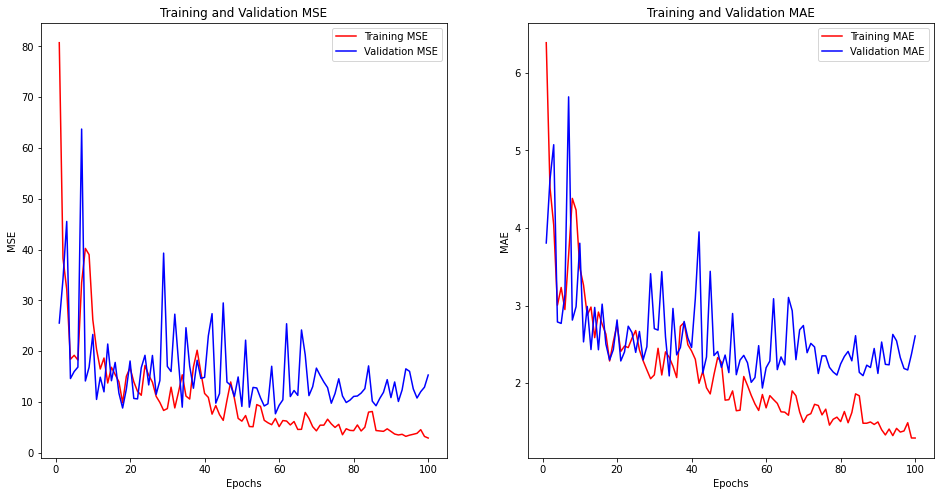

In [26]:
# plotando os resultados obtidos
fig, axes = plt.subplots(1, 2, squeeze = False, figsize = (16,8))

history_dict = hist.history

# loss - MSE
train_loss_values = history_dict["loss"]
val_loss_values = history_dict["val_loss"]

# epochs
epochs = range(1, len(train_loss_values) + 1)

# metrica - MAE
train_mae_values = history_dict["mae"]
val_mae_values = history_dict["val_mae"]

ax = axes.flat[0]
ax.plot(epochs, train_loss_values, "r", label = "Training MSE")
ax.plot(epochs, val_loss_values, "b", label = "Validation MSE")
ax.set_title("Training and Validation MSE")
ax.set_xlabel("Epochs")
ax.set_ylabel("MSE")
ax.legend()

ax = axes.flat[1]
ax.plot(epochs, train_mae_values, "r", label = "Training MAE")
ax.plot(epochs, val_mae_values, "b", label = "Validation MAE")
ax.set_title("Training and Validation MAE")
ax.set_xlabel("Epochs")
ax.set_ylabel("MAE")
ax.legend()

## <span style='color:blue'>Questão 4: [Valor da Questão: 2.0][Taxa de acerto: x.x]</span>

* Comente os resultados obtidos nos gráficos acima. Houve overfitting? Se sim, o que pode ser feito para melhorar a qualidade do modelo?

## <span style='color:green'>Respostas da Questão 4:</span>

* Observando o gráfico acima, Tanto o valor de **MSE** quanto no valor de **MAE**, os resultadados nos dados de Validação foram inferiores em relação aos Dados de Treinamento. Desse modo, há um indício de Sobreajuste (*Overfitting*) com os Dados de Treinamento. Alguns fatores podem ser considerados na hora de reduzir o sobreajuste do modelo, são eles:
    * a. Aumentar a quantidade de Dados de Treinamento, considerando dados mais representativos;
    * b. Utilizar técnicas de Dropout para zerar alguns neurônios da camada de forma intensional;
    * c. Reduzir o número de neurônios utilizados nas camadas ocultas; 

## <span style='color:blue'>Questão 5: [Valor da Questão: 2.0][Taxa de acerto: x.x]</span>

* Modifique hiperparâmetros do modelo como o número de camadas, as funções de ativação, o número de épocas utilizadas e o tamanho dos lotes. Comente os resultados obtidos a partir das mudanças realizadas. Utilize várias células para dividir as etapas de construção dos modelos.

In [27]:
def build_model( n_inputs, n_outputs ):
    
    # instanciando a construção do modelo de forma sequencial
    rede = Sequential()
    # adicionando uma camada densa com 64 neurônios e função de ativação relu
    # essa camada procede uma camada de entrada com n_inputs neurônios  
    rede.add(Dense(units = 64, activation = "relu", input_shape = (n_inputs,)))
    # adicionando uma camada densa com 64 neurônios e função de ativação relu
    rede.add(Dense(units = 64, activation = "relu"))
    # adicionando uma camada de dropout para zerar 20% dos neurônios da camda precessora 
    rede.add(Dropout(rate=0.2))
    # adicionando uma camada densa de saida com n_outputs neurônios e função de ativação linar 
    rede.add(Dense(units = n_outputs))
    
    return rede

model = build_model(13, 1)
model.compile( optimizer = SGD(learning_rate=0.001, momentum=0.0), loss = "mse", metrics=["mae"] )

hist = model.fit( x = train_data, 
                  y = train_targets, 
                  epochs = 100, 
                  batch_size = 4, 
                  steps_per_epoch = len(train_data) // 4,
                  validation_data = ( val_data, val_targets ), 
                  verbose = 1)

Epoch 1/100
75/75 [==============================] - 1s 4ms/step - loss: 119.9236 - mae: 7.6990 - val_loss: 20.0936 - val_mae: 3.1251
Epoch 2/100
75/75 [==============================] - 0s 2ms/step - loss: 27.7047 - mae: 3.7075 - val_loss: 13.9005 - val_mae: 2.7141
Epoch 3/100
75/75 [==============================] - 0s 2ms/step - loss: 24.6261 - mae: 3.6625 - val_loss: 13.3871 - val_mae: 2.7679
Epoch 4/100
75/75 [==============================] - 0s 2ms/step - loss: 20.8963 - mae: 3.3756 - val_loss: 14.2059 - val_mae: 2.8977
Epoch 5/100
75/75 [==============================] - 0s 2ms/step - loss: 22.5257 - mae: 3.4263 - val_loss: 10.5908 - val_mae: 2.3252
Epoch 6/100
75/75 [==============================] - 0s 2ms/step - loss: 16.4616 - mae: 3.1471 - val_loss: 20.0281 - val_mae: 3.2845
Epoch 7/100
75/75 [==============================] - 0s 2ms/step - loss: 18.2111 - mae: 3.1349 - val_loss: 29.5423 - val_mae: 3.9355
Epoch 8/100
75/75 [==============================] - 0s 2ms/step - l

Epoch 62/100
75/75 [==============================] - 0s 2ms/step - loss: 9.9374 - mae: 2.2198 - val_loss: 12.0717 - val_mae: 2.4424
Epoch 63/100
75/75 [==============================] - 0s 2ms/step - loss: 8.1271 - mae: 2.1914 - val_loss: 12.9352 - val_mae: 2.6181
Epoch 64/100
75/75 [==============================] - 0s 2ms/step - loss: 9.2317 - mae: 2.2584 - val_loss: 14.5398 - val_mae: 2.6984
Epoch 65/100
75/75 [==============================] - 0s 2ms/step - loss: 9.3497 - mae: 2.2825 - val_loss: 14.1107 - val_mae: 2.5940
Epoch 66/100
75/75 [==============================] - 0s 2ms/step - loss: 8.9647 - mae: 2.1797 - val_loss: 16.4328 - val_mae: 2.7493
Epoch 67/100
75/75 [==============================] - 0s 2ms/step - loss: 8.2043 - mae: 2.1617 - val_loss: 13.3907 - val_mae: 2.6175
Epoch 68/100
75/75 [==============================] - 0s 2ms/step - loss: 9.7045 - mae: 2.3562 - val_loss: 15.0886 - val_mae: 2.8028
Epoch 69/100
75/75 [==============================] - 0s 2ms/step - l

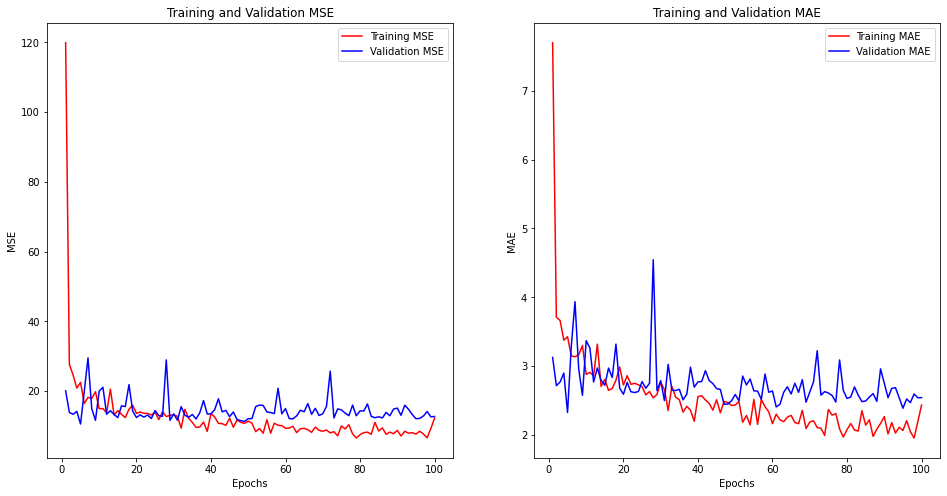

In [28]:
# plotando os resultados obtidos
fig, axes = plt.subplots(1, 2, squeeze = False, figsize = (16,8))

history_dict = hist.history

# loss - MSE
train_loss_values = history_dict["loss"]
val_loss_values = history_dict["val_loss"]

# epochs
epochs = range(1, len(train_loss_values) + 1)

# metrica - MAE
train_mae_values = history_dict["mae"]
val_mae_values = history_dict["val_mae"]

ax = axes.flat[0]
ax.plot(epochs, train_loss_values, "r", label = "Training MSE")
ax.plot(epochs, val_loss_values, "b", label = "Validation MSE")
ax.set_title("Training and Validation MSE")
ax.set_xlabel("Epochs")
ax.set_ylabel("MSE")
ax.legend()

ax = axes.flat[1]
ax.plot(epochs, train_mae_values, "r", label = "Training MAE")
ax.plot(epochs, val_mae_values, "b", label = "Validation MAE")
ax.set_title("Training and Validation MAE")
ax.set_xlabel("Epochs")
ax.set_ylabel("MAE")
ax.legend()

## <span style='color:green'>Respostas da Questão 5:</span>

* Observando o histórico de treinamento acima, é perceptível que o sobreajuste foi minizado através de algumas mudanças nos hiperparâmetros do modelo. Ou seja, as funções de erro nos Dados de Validação foram minimizados e ficaram aproximadamente semelhante aos valores obtidos com os Dados de Treinamemento. Além disso, podemos considerar que esse ganho é uma forma de tornar a rede mais generalista, em que ela consegue obter previsões mais satisfatórios em dados que distoam dos utilizados no Treinamento do modelo.

### Teste do modelo

O teste do modelo pode ser realizado a partir da função **evaluate**, que recebe os dados de treino e retorna o valor de loss calculado para esse conjunto e os valores de cada métrica da lista fornecida durante a compilação do modelo. 

* É uma prática comum realizar ajustes no modelo com base no conjunto de validação e só utilizar o conjunto de testes após a definição dos hiperparâmetros definitivos.
* Como os hiperparâmetros são ajustados a partir dos resultados obtidos para o conjunto de validação, o modelo pode acabar. sobreajustando aos dados de validação, então é interessante mudar os dados desse conjunto com frequência.
* Para mudar os dados de validação basta alterar a semente na função train_test_split.
* Crie um novo modelo do zero após a realização de mudanças nos conjuntos de treino/validação.

In [29]:
test_mse, test_mae = model.evaluate( test_data, test_targets)

# observa-se que os dados de saída são normalizados em milhares de dólares, 
# então é necessário multiplicar por 1000 para obter os valores absolutos
print("Erro médio absoluto de teste: ${:.2f}".format(1000*test_mae))

4/4 [==============================] - 0s 2ms/step - loss: 17.3968 - mae: 2.8829
Erro médio absoluto de teste: $2882.91


## <span style='color:blue'>Questão 6: [Valor da Questão: 1.0][Taxa de acerto: x.x]</span>

* Verifique novamente a faixa de valores dos gabaritos no banco de dados. Considerando a extensão dessa faixa de valores, pode-se dizer que as predições do modelo são significativas?

In [30]:
# IMPLEMENTE SEU CÓDIGO AQUI --> QUESTÃO 6
min_train_x = np.min(train_targets, axis=0)
max_train_x = np.max(train_targets, axis=0)
mean_train_x = np.mean(train_targets, axis=0)
var_train_x = np.var(train_targets, axis=0)

print('{} - Limite: [${:.2f}, ${:.2f}], com Média ${:.2f} e Variância {:.2f}'.format(14, min_train_x*1000, 
                                                                                     max_train_x*1000,
                                                                                     mean_train_x*1000, 
                                                                                     var_train_x))

min_train_x = np.min(test_targets, axis=0)
max_train_x = np.max(test_targets, axis=0)
mean_train_x = np.mean(test_targets, axis=0)
var_train_x = np.var(test_targets, axis=0)

print('{} - Limite: [${:.2f}, ${:.2f}], com Média ${:.2f} e Variância {:.2f}'.format(14, min_train_x*1000, 
                                                                                     max_train_x*1000,
                                                                                     mean_train_x*1000, 
                                                                                     var_train_x))
print("Erro médio absoluto de teste: ${:.2f}".format(1000*test_mae))

14 - Limite: [$5000.00, $50000.00], com Média $22868.54 e Variância 90.36
14 - Limite: [$5600.00, $50000.00], com Média $23078.43 e Variância 83.24
Erro médio absoluto de teste: $2882.91


## <span style='color:green'>Resposta da Questão 6:</span>

* Observando os valores médios obtidos nos Dados de Treinamento e nos Dados de Teste em comparação com o erro médio absoluto com os Dados de Teste (previsão do algoritmo), e analisando esses valores com os limites obtidos nos Dados de Treino e Teste, fica perceptível que as predições realizadas pelo algoritmo estão consistentes com os dados de referência utilizados, un indício de que o modelo desenvolvido não apresenta erros durante o desenvolvimento. Além disso, o baixo valor nas Funções de Erro (**MSE** e **MAE**) indicam que o modelo desenvolvido possui um bom desempenho (1.4-h).

### Referências
* Chollet, Francois. Deep learning with Python. Simon and Schuster, 2017.

![gif3](https://user-images.githubusercontent.com/58775072/142712798-3c5ce76c-8d6f-4345-8d65-2be3f7aa2ae9.gif)